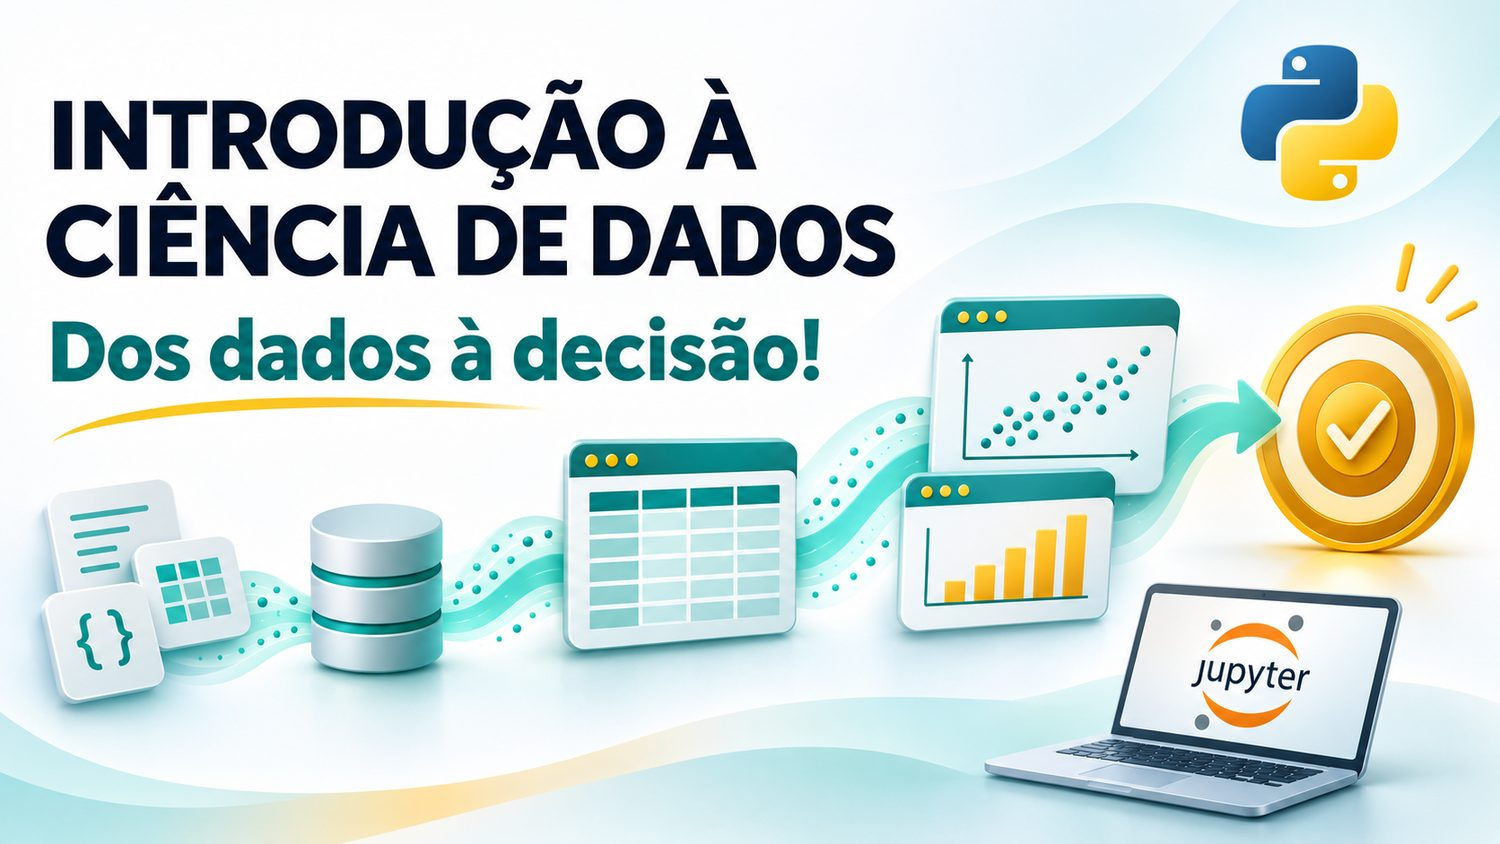

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_6_modelos_supervisionados/02_KNN_Classificacao.ipynb)

# Capítulo 2 – K vizinhos mais próximos: classificação

O primeiro modelo deste módulo é talvez o mais intuitivo de todos: para prever o que vai acontecer com um caso novo, procura os casos **mais parecidos** que já viste e vê o que lhes aconteceu. Chama-se **K vizinhos mais próximos**, ou **KNN** (*k-nearest neighbors*). Neste capítulo construímo-lo de raiz em NumPy e só depois usamos a versão do scikit-learn.

> **Objetivos:** explicar a ideia de aprender por semelhança; calcular distâncias entre observações; implementar o KNN com votação maioritária; perceber porque é obrigatório pôr os atributos na mesma escala; ver o efeito de k na fronteira de decisão; escolher k com dados de validação; conhecer os pontos fortes e as limitações do método.

**Pré-requisitos:** capítulo 1, e o módulo 4 (escalas e divisão dos dados). A sintaxe do scikit-learn está em [Scikit-Learn: classificação](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_2_avancado/N2_04_ScikitLearn_Classificacao.ipynb), e as operações com arrays em [NumPy](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_1_introducao/22_NumPy.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_entregas(n=4000, semente=29):
    """Gera entregas de uma empresa fictícia de distribuição urbana (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    distancia = rng.gamma(2.2, 2.6, n).clip(0.4, 25).round(1)
    hora = rng.uniform(8, 21, n).round(2)
    paragens = rng.poisson(1.2, n)
    peso = rng.gamma(1.6, 3.0, n).clip(0.1, 30).round(1)
    chuva = rng.random(n) < 0.2
    zona = rng.choice(["centro", "periferia", "rural"], n, p=[0.5, 0.35, 0.15])
    veiculo = np.where(distancia < 3, rng.choice(["bicicleta", "mota"], n, p=[0.6, 0.4]),
                       rng.choice(["mota", "carrinha"], n, p=[0.55, 0.45]))
    hora_de_ponta = ((hora >= 8) & (hora < 9.5)) | ((hora >= 17) & (hora < 19.5))
    transito = np.where(hora_de_ponta, np.where(zona == "centro", 1.75, 1.45), 1.0)
    por_km = np.select([veiculo == "bicicleta", veiculo == "mota"], [4.2, 2.9], 3.3)
    tempo = (7 + distancia * por_km * transito * np.where(chuva, 1.25, 1.0) * np.where(zona == "rural", 0.85, 1.0)
             + 4.0 * paragens + 0.15 * peso + rng.normal(0, 3.5, n))
    tempo = np.where(rng.random(n) < 0.015, tempo + rng.uniform(40, 120, n), tempo)       # avarias e enganos de morada
    prometido = 16 + 3.6 * distancia + 4.0 * paragens
    return pd.DataFrame({"distancia_km": distancia, "hora": hora, "paragens": paragens, "peso_kg": peso,
                         "chuva": chuva, "zona": zona, "veiculo": veiculo,
                         "tempo_min": tempo.clip(4).round(1), "atrasada": tempo > prometido})


entregas = gerar_entregas()
entregas.head()

,distancia_km,hora,paragens,peso_kg,chuva,zona,veiculo,tempo_min,atrasada
0,3.6,9.05,3,2.2,False,periferia,carrinha,35.7,False
1,4.3,16.95,0,12.8,False,centro,mota,25.3,False
2,5.1,14.79,1,3.9,True,periferia,carrinha,34.0,False
3,6.0,8.43,1,9.8,False,periferia,mota,44.0,True
4,7.2,14.07,0,2.4,False,centro,mota,33.5,False


## A ideia: diz-me com quem andas

Para ver o método a funcionar, começamos com apenas dois atributos, a distância e a hora de saída, e com poucas entregas. Chega uma entrega nova: 9 km, a sair às 18h. Vai atrasar?

Treino: 2400 | Validação: 800 | Teste: 800


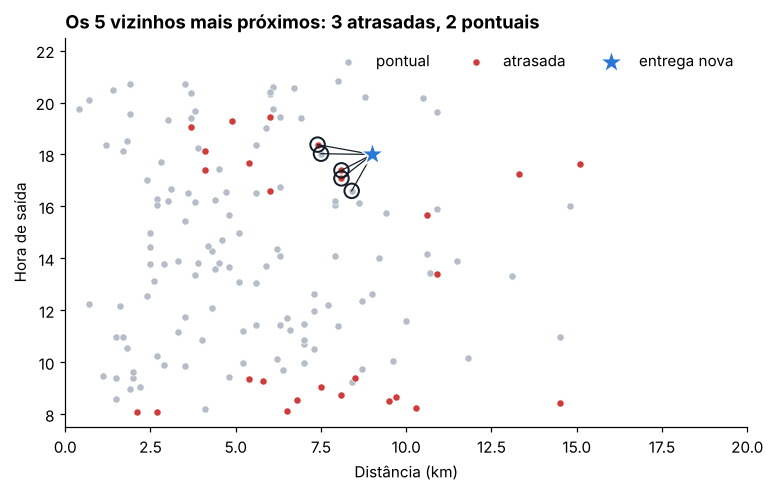

In [3]:
from sklearn.model_selection import train_test_split

treino, resto = train_test_split(entregas, test_size=0.4, random_state=0, stratify=entregas["atrasada"])
validacao, teste = train_test_split(resto, test_size=0.5, random_state=0, stratify=resto["atrasada"])
print(f"Treino: {len(treino)} | Validação: {len(validacao)} | Teste: {len(teste)}")

amostra = treino.sample(150, random_state=4)
nova = np.array([9.0, 18.0])


def pontos(ax, dados, tamanho=22, alfa=1.0):
    for valor, cor, rotulo in [(False, CINZA, "pontual"), (True, MAU, "atrasada")]:
        d = dados[dados["atrasada"] == valor]
        ax.scatter(d["distancia_km"], d["hora"], s=tamanho, color=cor, alpha=alfa, label=rotulo, edgecolor="white", linewidth=0.4)
    ax.set_xlabel("Distância (km)")
    ax.set_ylabel("Hora de saída")


distancias = np.sqrt((amostra["distancia_km"] - nova[0]) ** 2 + (amostra["hora"] - nova[1]) ** 2)
vizinhos = amostra.loc[distancias.nsmallest(5).index]

fig, ax = plt.subplots(figsize=(8, 4.6))
pontos(ax, amostra)
for _, v in vizinhos.iterrows():
    ax.plot([nova[0], v["distancia_km"]], [nova[1], v["hora"]], color=TINTA, lw=0.8, zorder=1)
ax.scatter(vizinhos["distancia_km"], vizinhos["hora"], s=90, facecolor="none", edgecolor=TINTA, lw=1.3)
ax.scatter(*nova, marker="*", s=260, color=AZUL, edgecolor="white", zorder=4, label="entrega nova")
ax.set_xlim(0, 20)
ax.set_ylim(7.5, 22.5)
ax.legend(frameon=False, loc="upper right", ncol=3)
ax.set_title(f"Os 5 vizinhos mais próximos: {int(vizinhos['atrasada'].sum())} atrasadas, {int((~vizinhos['atrasada']).sum())} pontuais")
plt.show()

O algoritmo tem três passos:

1. **medir a distância** da entrega nova a todas as entregas conhecidas;
2. **ficar com as k mais próximas** (aqui, k = 5);
3. **votar**: a classe mais frequente entre os vizinhos é a previsão.

Não há mais nada. O KNN não tem uma fase de treino propriamente dita: limita-se a **guardar os dados**, e todo o trabalho é feito no momento da previsão. Por isso lhe chamam um método «preguiçoso» (*lazy learner*), ou **baseado em instâncias**.

## Passo 1 – Medir distâncias

«Parecido» precisa de uma definição numérica. A mais usada é a **distância euclidiana**, a do teorema de Pitágoras: a raiz quadrada da soma dos quadrados das diferenças.

| Distância | Cálculo | Ideia |
| --- | --- | --- |
| **Euclidiana** | √(Σ diferença²) | Em linha reta |
| **Manhattan** | Σ \|diferença\| | Pelas ruas de uma cidade em quadrícula |

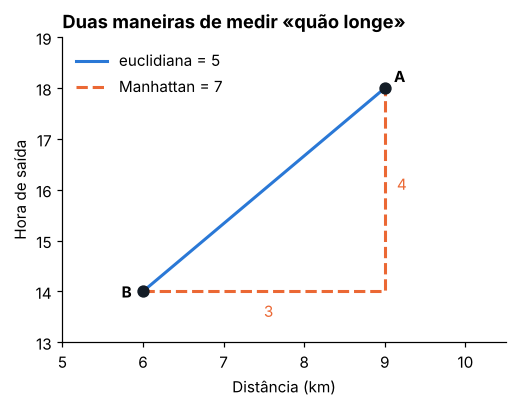

In [4]:
a = np.array([9.0, 18.0])        # 9 km, 18h00
b = np.array([6.0, 14.0])        # 6 km, 14h00

euclidiana = np.sqrt(np.sum((a - b) ** 2))
manhattan = np.sum(np.abs(a - b))

fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.plot([b[0], a[0]], [b[1], a[1]], color=AZUL, lw=2, label=f"euclidiana = {euclidiana:.0f}")
ax.plot([b[0], a[0], a[0]], [b[1], b[1], a[1]], color=LARANJA, lw=2, ls="--", label=f"Manhattan = {manhattan:.0f}")
ax.scatter([a[0], b[0]], [a[1], b[1]], color=TINTA, s=50, zorder=3)
ax.annotate("A", a, textcoords="offset points", xytext=(6, 4), fontweight="bold")
ax.annotate("B", b, textcoords="offset points", xytext=(-14, -4), fontweight="bold")
ax.text(7.5, 13.5, "3", color=LARANJA)
ax.text(9.15, 16, "4", color=LARANJA)
ax.set_xlabel("Distância (km)")
ax.set_ylabel("Hora de saída")
ax.set_xlim(5, 10.5)
ax.set_ylim(13, 19)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Duas maneiras de medir «quão longe»")
plt.show()

### O problema das escalas

A conta acima somou **quilómetros com horas**. Funcionou porque as duas colunas têm, por acaso, amplitudes parecidas. Se juntássemos o peso em gramas, uma diferença de 500 g esmagaria qualquer diferença de horas, e o modelo passaria a procurar «entregas com o mesmo peso».

O KNN não sabe o que os números significam: um atributo com valores maiores **pesa mais** na distância. Por isso, antes de um KNN, os atributos são sempre postos na mesma escala (módulo 4, capítulo 4), com a média e o desvio-padrão **do treino**.

In [5]:
atributos = ["distancia_km", "hora"]
media, desvio = treino[atributos].mean().to_numpy(), treino[atributos].std().to_numpy()


def normalizar(tabela):
    """Converte para pontuações z, com a média e o desvio-padrão do treino."""
    return (np.asarray(tabela, dtype=float) - media) / desvio


X_treino, y_treino = normalizar(treino[atributos]), treino["atrasada"].to_numpy()
X_validacao, y_validacao = normalizar(validacao[atributos]), validacao["atrasada"].to_numpy()
X_teste, y_teste = normalizar(teste[atributos]), teste["atrasada"].to_numpy()
print("A entrega nova, normalizada:", normalizar(nova).round(2))

A entrega nova, normalizada: [0.92 0.95]


## Passos 2 e 3 – Encontrar os vizinhos e votar

Com o NumPy, o algoritmo inteiro cabe em poucas linhas. O `argsort` devolve as posições que ordenariam as distâncias; ficamos com as k primeiras.

In [6]:
def knn_prever_um(x, X, y, k):
    """Prevê a classe de uma observação x a partir dos k vizinhos mais próximos em (X, y)."""
    distancias = np.sqrt(((X - x) ** 2).sum(axis=1))      # 1. distância a todos os pontos de treino
    vizinhos = np.argsort(distancias)[:k]                 # 2. posições dos k mais próximos
    return y[vizinhos].mean() > 0.5                       # 3. votação: a maioria é «atrasada»?


for k in [1, 5, 25]:
    print(f"k = {k:>2}: a entrega nova é prevista como {'ATRASADA' if knn_prever_um(normalizar(nova), X_treino, y_treino, k) else 'pontual'}")

k =  1: a entrega nova é prevista como ATRASADA
k =  5: a entrega nova é prevista como ATRASADA
k = 25: a entrega nova é prevista como ATRASADA


Para prever muitas entregas de uma vez, repetimos para cada uma. E comparamos com a implementação do scikit-learn, que deve dar exatamente o mesmo.

In [7]:
from sklearn.neighbors import KNeighborsClassifier


def knn_prever(X_novos, X, y, k):
    return np.array([knn_prever_um(x, X, y, k) for x in X_novos])


nosso = knn_prever(X_validacao, X_treino, y_treino, k=15)
oficial = KNeighborsClassifier(n_neighbors=15).fit(X_treino, y_treino).predict(X_validacao)
print(f"Exatidão do nosso KNN:       {(nosso == y_validacao).mean():.3f}")
print(f"Exatidão do scikit-learn:    {(oficial == y_validacao).mean():.3f}")
print(f"Previsões iguais nas duas:   {(nosso == oficial).mean():.1%}")

Exatidão do nosso KNN:       0.875
Exatidão do scikit-learn:    0.875
Previsões iguais nas duas:   100.0%


As duas versões fazem as mesmas previsões. A do scikit-learn é mais rápida (usa estruturas de dados que evitam medir a distância a todos os pontos) e traz opções que veremos adiante. Daqui em diante usamos essa.

> Com um número **par** de vizinhos e duas classes pode haver empates. Usa-se por isso um k **ímpar**.

## A fronteira de decisão

Para ver o que o modelo aprendeu, perguntamos-lhe a previsão para **todos** os pontos do plano e pintamos o resultado. À linha que separa as duas zonas chama-se **fronteira de decisão**.

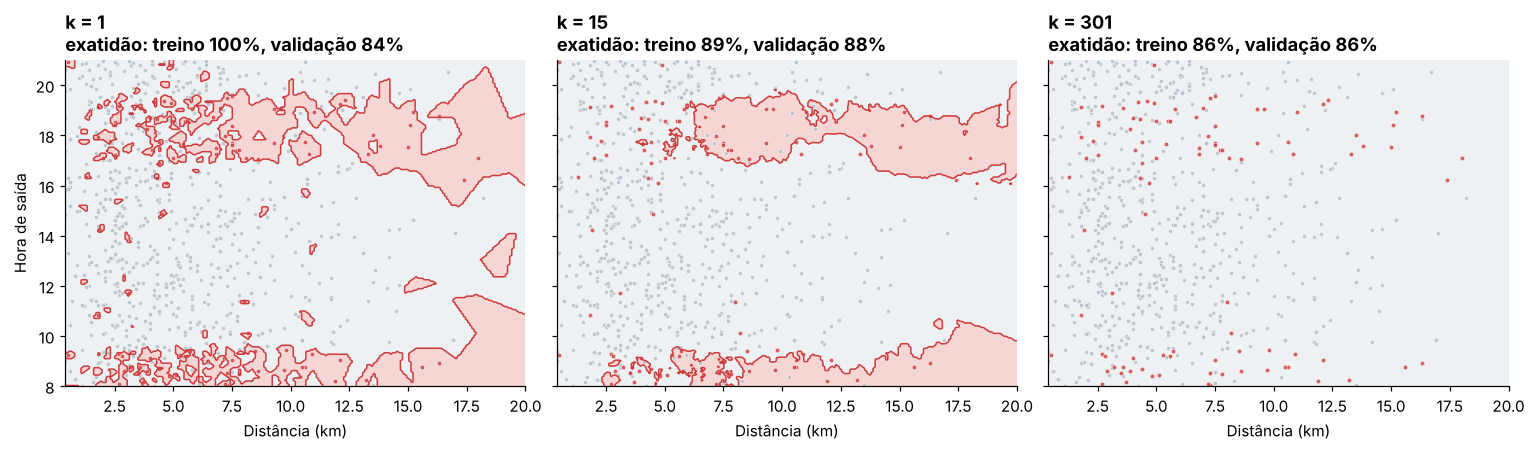

In [8]:
grelha_x, grelha_y = np.meshgrid(np.linspace(0.4, 20, 220), np.linspace(8, 21, 220))
grelha = normalizar(np.column_stack([grelha_x.ravel(), grelha_y.ravel()]))
visiveis = treino.sample(700, random_state=1)


def fronteira(ax, modelo, titulo):
    prob = modelo.predict_proba(grelha)[:, 1].reshape(grelha_x.shape)
    ax.contourf(grelha_x, grelha_y, prob, levels=[0, 0.5, 1], colors=["#eef1f4", "#f6d5d5"])
    ax.contour(grelha_x, grelha_y, prob, levels=[0.5], colors=[MAU], linewidths=1)
    pontos(ax, visiveis, tamanho=9, alfa=0.8)
    ax.set_xlim(0.4, 20)
    ax.set_title(titulo)


fig, eixos = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, k in zip(eixos, [1, 15, 301]):
    modelo = KNeighborsClassifier(n_neighbors=k).fit(X_treino, y_treino)
    fronteira(ax, modelo, f"k = {k}\nexatidão: treino {modelo.score(X_treino, y_treino):.0%}, validação {modelo.score(X_validacao, y_validacao):.0%}")
    if ax is not eixos[0]:
        ax.set_ylabel("")
plt.tight_layout()
plt.show()

As zonas rosa são onde o modelo prevê «atrasada». O padrão geral é o mesmo nos três: os atrasos concentram-se nas **horas de ponta** (de manhã cedo e ao fim da tarde) e nas distâncias maiores. Uma regressão logística, que só sabe traçar uma linha reta, nunca encontraria estas duas faixas horizontais. O KNN encontra-as sem que ninguém lhe diga que existem horas de ponta.

O que muda com k é o **grau de pormenor**:

- com **k = 1**, cada ponto de treino manda na sua vizinhança. A fronteira enche-se de pequenas ilhas à volta de casos isolados. O modelo acerta 100% do treino (cada ponto é o vizinho mais próximo de si próprio) e isso não quer dizer nada;
- com **k = 15**, a votação alisa o ruído e ficam as duas faixas;
- com **k = 301**, a votação é dominada pela classe maioritária. As faixas desaparecem e o modelo prevê «pontual» em toda a parte: voltámos à linha de base.

## Escolher k

O valor de k não se aprende com os dados de treino: é uma escolha nossa, a que se chama **hiperparâmetro**. Escolhe-se experimentando vários valores e medindo o desempenho em dados de **validação**.

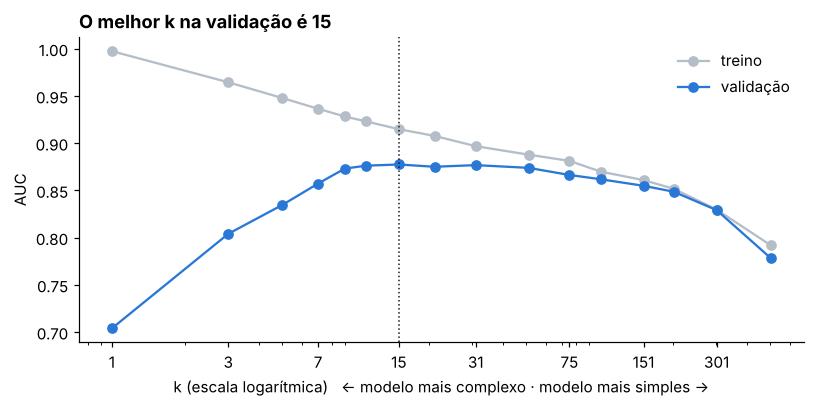

In [9]:
from sklearn.metrics import f1_score, roc_auc_score

valores_k = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51, 75, 101, 151, 201, 301, 501]
curva = []
for k in valores_k:
    modelo = KNeighborsClassifier(n_neighbors=k).fit(X_treino, y_treino)
    curva.append({"k": k, "treino": roc_auc_score(y_treino, modelo.predict_proba(X_treino)[:, 1]),
                  "validação": roc_auc_score(y_validacao, modelo.predict_proba(X_validacao)[:, 1])})
curva = pd.DataFrame(curva).set_index("k")
melhor_k = int(curva["validação"].idxmax())

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(curva.index, curva["treino"], "o-", color=CINZA, label="treino")
ax.plot(curva.index, curva["validação"], "o-", color=AZUL, label="validação")
ax.axvline(melhor_k, color=TINTA, ls=":", lw=1)
ax.set_xscale("log")
ax.set_xticks([1, 3, 7, 15, 31, 75, 151, 301], [1, 3, 7, 15, 31, 75, 151, 301])
ax.set_xlabel("k (escala logarítmica)   ← modelo mais complexo · modelo mais simples →")
ax.set_ylabel("AUC")
ax.set_title(f"O melhor k na validação é {melhor_k}")
ax.legend(frameon=False)
plt.show()

Medimos com a **AUC** (capítulo 1), que avalia a fração de vizinhos atrasados em todos os limiares de uma vez, e por isso oscila menos do que uma métrica calculada num só limiar.

A curva do treino desce sempre: parte de um valor perfeito com k = 1 e piora à medida que o modelo fica mais simples. A da validação sobe depressa, atinge um máximo e depois desce devagar. É essa que interessa.

- À esquerda do máximo, o modelo segue o ruído do treino: é o **sobreajuste**. A distância entre as duas curvas mostra-o.
- À direita, o modelo vai ficando demasiado simples para captar o padrão: é o **subajuste**.

Vamos estudar este compromisso em pormenor no capítulo 5. Repara que o topo da curva é plano: muitos valores de k dão resultados quase iguais, e a diferença entre eles é em parte acaso da amostra de validação. No capítulo 6 veremos uma forma mais estável de fazer esta escolha.

## Com todos os atributos

Até aqui usámos dois atributos para poder desenhar. O KNN funciona da mesma forma com mais: a distância passa a somar mais diferenças. Usamos a preparação do módulo 4, dentro de um pipeline.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numericas, nominais = ["distancia_km", "hora", "paragens", "peso_kg", "chuva"], ["zona", "veiculo"]


def knn_completo(k, colunas_numericas=numericas, colunas_nominais=nominais, **opcoes):
    preparacao = ColumnTransformer([("num", StandardScaler(), colunas_numericas), ("cat", OneHotEncoder(), colunas_nominais)])
    return make_pipeline(preparacao, KNeighborsClassifier(n_neighbors=k, **opcoes))


todas = numericas + nominais
candidatos = {"Distância e hora": (["distancia_km", "hora"], []),
              "+ chuva, zona e veículo": (["distancia_km", "hora", "chuva"], nominais),
              "+ paragens": (["distancia_km", "hora", "chuva", "paragens"], nominais),
              "+ peso (todos os atributos)": (numericas, nominais)}
linhas = []
for nome, (nums, noms) in candidatos.items():
    modelo = knn_completo(melhor_k, nums, noms).fit(treino[todas], treino["atrasada"])
    fracao = modelo.predict_proba(validacao[todas])[:, 1]
    linhas.append({"Atributos": nome, "AUC": roc_auc_score(y_validacao, fracao), "F1": f1_score(y_validacao, fracao > 0.5)})
pd.DataFrame(linhas).set_index("Atributos").round(3)

,AUC,F1
Atributos,,
Distância e hora,0.877,0.485
"+ chuva, zona e veículo",0.872,0.447
+ paragens,0.806,0.267
+ peso (todos os atributos),0.777,0.194


Acrescentar atributos **nem sempre ajuda** um KNN, e aqui acaba por prejudicar. A chuva, a zona e o veículo não mudam o resultado de forma visível; as paragens e o peso pioram-no bastante.

Cada atributo entra na distância com o mesmo peso, seja útil ou não.

- O **peso** da encomenda quase não influencia o tempo de entrega.
- As **paragens** aumentam o tempo, mas a hora prometida já conta com elas, e por isso pouco dizem sobre o **atraso**.

Estes dois atributos afastam entregas que, no que interessa, eram vizinhas, e aproximam outras que só têm em comum o peso ou o número de paragens.

É uma diferença importante em relação a outros modelos: uma árvore de decisão ignora sozinha os atributos inúteis; um KNN não. **Num KNN, a seleção de atributos faz parte do modelo**, e faz-se com conhecimento do problema e com a validação.

## Votos com peso

Na votação simples, o 15.º vizinho vale tanto como o 1.º. Uma variante dá mais peso aos vizinhos mais próximos: cada voto é ponderado pelo **inverso da distância**. No scikit-learn, é a opção `weights="distance"`.

In [11]:
uteis = ["distancia_km", "hora"]          # entre dois modelos equivalentes na validação, ficamos com o mais simples
linhas = []
for pesos in ["uniform", "distance"]:
    for metrica in ["euclidean", "manhattan"]:
        modelo = knn_completo(melhor_k, uteis, [], weights=pesos, metric=metrica).fit(treino[todas], treino["atrasada"])
        fracao = modelo.predict_proba(validacao[todas])[:, 1]
        linhas.append({"votos": pesos, "distância": metrica, "AUC": roc_auc_score(y_validacao, fracao), "F1": f1_score(y_validacao, fracao > 0.5)})
pd.DataFrame(linhas).round(3)

,votos,distância,AUC,F1
0,uniform,euclidean,0.877,0.485
1,uniform,manhattan,0.882,0.489
2,distance,euclidean,0.864,0.498
3,distance,manhattan,0.865,0.505


As diferenças são pequenas, muito menores do que as da tabela anterior. A escolha de k e dos atributos conta mais do que estas opções, e é aí que vale a pena gastar tempo. Mantemos a votação simples.

## O teste, uma só vez

Escolhidos os atributos (distância e hora) e o valor de k com a validação, medimos o modelo final no teste.

In [12]:
from sklearn.metrics import precision_score, recall_score

final = knn_completo(melhor_k, uteis, []).fit(treino[todas], treino["atrasada"])
previsto = final.predict(teste[todas])
print(f"KNN com k = {melhor_k}, no teste ({len(teste)} entregas, {y_teste.mean():.1%} atrasadas)")
print(f"  exatidão      {(previsto == y_teste).mean():.1%}   (dizer sempre «pontual»: {1 - y_teste.mean():.1%})")
print(f"  sensibilidade {recall_score(y_teste, previsto):.1%}")
print(f"  precisão      {precision_score(y_teste, previsto):.1%}")
print(f"  F1            {f1_score(y_teste, previsto):.2f}")
print(f"  AUC           {roc_auc_score(y_teste, final.predict_proba(teste[todas])[:, 1]):.2f}")

KNN com k = 15, no teste (800 entregas, 14.5% atrasadas)
  exatidão      87.4%   (dizer sempre «pontual»: 85.5%)
  sensibilidade 42.2%
  precisão      59.0%
  F1            0.49
  AUC           0.84


## Pontos fortes e limitações

| Pontos fortes | Limitações |
| --- | --- |
| Simples de explicar: «as entregas mais parecidas com esta atrasaram» | Lento a prever com muitos dados: cada previsão compara com todo o treino |
| Não assume nenhuma forma para a fronteira; adapta-se a padrões irregulares | Sensível à escala e aos atributos irrelevantes |
| Um só hiperparâmetro principal | Piora com muitos atributos (a «maldição da dimensionalidade», no próximo capítulo) |
| Sem fase de treino; juntar dados novos é imediato | Tem de guardar todos os dados de treino |
| Serve para classificação e para regressão | Não diz que atributos são importantes |

## Exercícios

### `Exercício 1` – À mão

Tens cinco entregas conhecidas, já normalizadas, e uma nova no ponto (0, 0). Calcula a distância euclidiana a cada uma e indica a previsão com k = 1 e com k = 3.

| Entrega | x1 | x2 | Atrasada |
| --- | --- | --- | --- |
| A | 1 | 0 | sim |
| B | 0 | −2 | não |
| C | −1 | 1 | não |
| D | 2 | 2 | sim |
| E | −0,5 | 0 | não |

<details>
<summary><b>Ver uma solução possível</b></summary>

Distâncias: A = 1; B = 2; C = √2 ≈ 1,41; D = √8 ≈ 2,83; E = 0,5.

- k = 1: o vizinho mais próximo é E (pontual) → **pontual**.
- k = 3: os três mais próximos são E (não), A (sim) e C (não) → dois votos contra um → **pontual**.

</details>

### `Exercício 2` – A distância de Manhattan

Altera a função `knn_prever_um` para aceitar um parâmetro `distancia` com os valores `"euclidiana"` ou `"manhattan"`. Compara a exatidão das duas na validação, com k = 15.

In [13]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def knn_um(x, X, y, k, distancia="euclidiana"):
    d = np.sqrt(((X - x) ** 2).sum(axis=1)) if distancia == "euclidiana" else np.abs(X - x).sum(axis=1)
    return y[np.argsort(d)[:k]].mean() > 0.5


for nome in ["euclidiana", "manhattan"]:
    previsto = np.array([knn_um(x, X_treino, y_treino, 15, nome) for x in X_validacao])
    print(f"{nome}: {(previsto == y_validacao).mean():.3f}")
```

As duas dão resultados muito próximos. Com poucos atributos, a escolha da distância raramente é decisiva.

</details>

### `Exercício 3` – O que acontece sem normalizar?

Cria uma coluna `peso_g` (o peso em gramas). Treina um KNN com `distancia_km`, `hora` e `peso_g`, primeiro sem normalizar e depois com `StandardScaler`. Compara o F1 na validação e explica a diferença.

In [14]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
colunas = ["distancia_km", "hora", "peso_g"]
tr, va = treino.assign(peso_g=treino["peso_kg"] * 1000), validacao.assign(peso_g=validacao["peso_kg"] * 1000)
for nome, modelo in [("sem normalizar", KNeighborsClassifier(15)), ("com normalização", make_pipeline(StandardScaler(), KNeighborsClassifier(15)))]:
    modelo.fit(tr[colunas], tr["atrasada"])
    print(f"{nome}: F1 = {f1_score(va['atrasada'], modelo.predict(va[colunas])):.2f}")
```

Sem normalizar, o F1 fica perto de zero. O peso em gramas varia em milhares, e a distância e a hora em unidades: os «vizinhos» passam a ser simplesmente as entregas com o peso mais parecido, que nada diz sobre o atraso. Com a normalização, os três atributos contam o mesmo e o modelo volta a funcionar.

</details>

### `Exercício 4` – Mudar o limiar da votação

Com `predict_proba`, o KNN devolve a **fração de vizinhos atrasados**. Usa o modelo `final` e experimenta avisar quando essa fração for superior a 0,3 (em vez de 0,5). O que acontece à sensibilidade e à precisão, na validação?

In [15]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
fracao = final.predict_proba(validacao[todas])[:, 1]
for limiar in [0.5, 0.3]:
    previsto = fracao > limiar
    print(f"limiar {limiar}: sensibilidade {recall_score(y_validacao, previsto):.0%}, precisão {precision_score(y_validacao, previsto):.0%}")
```

Com um limiar mais baixo, bastam menos vizinhos atrasados para dar o aviso: a sensibilidade sobe e a precisão desce, como no capítulo 1. A «probabilidade» de um KNN só pode tomar k + 1 valores (0, 1/k, 2/k, …), o que a torna pouco fina quando k é pequeno.

</details>

## Verifica o que aprendeste

- [ ] Sei descrever os três passos do KNN.
- [ ] Sei calcular a distância euclidiana e a de Manhattan.
- [ ] Sei porque é obrigatório normalizar os atributos antes de um KNN.
- [ ] Sei implementar o KNN em NumPy.
- [ ] Sei ler uma fronteira de decisão.
- [ ] Sei o que acontece com um k muito pequeno e com um k muito grande.
- [ ] Sei o que é um hiperparâmetro e como se escolhe.
- [ ] Sei porque um atributo irrelevante prejudica um KNN.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/neighbors.html
- https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html
- https://en.wikipedia.org/wiki/K-nearest_neighbors_algorithm